# Phase I — Unified road segmentation (all architectures)

Route Resilience / ISRO BAH 2026.

Consolidates the seven separate Phase I notebooks (DeepLabV3+, UNet++, UNeXt, SegFormer-B1, DINOv2+FPN, MFuser-lite, SAM mask repair) into **one** modular notebook.

Same DeepGlobe split (seed 42, 80/20), same occlusion augmentations, and same BCE+Dice loss across every architecture, for a fair comparison — pick a model with the `MODEL_NAME` switch below and run all cells top to bottom.

| `MODEL_NAME` | Architecture | Masks folder | Checkpoint |
|---|---|---|---|
| `deeplabv3` | DeepLabV3+ (production) | `masks_deeplab/` | `best_road_model_deeplabv3.pth` |
| `unetpp` | UNet++ baseline | `masks_unetpp/` | `best_road_model_unetpp.pth` |
| `unext` | UNeXt (light / fast) | `masks_unext/` | `best_road_model_unext.pth` |
| `segformer` | SegFormer-B1 (MiT-B1) | `masks_segformer/` | `best_road_model_segformer_b1.pth` |
| `dinov2` | DINOv2 + FPN decoder | `masks_dinov2/` | `best_road_model_dinov2_fpn.pth` |
| `mfuser` | MFuser-lite (DINOv2 + CLIP fusion) | `masks_mfuser/` | `best_road_model_mfuser.pth` |

**SAM mask repair** is optional post-processing (no retraining) — run it after any model above has produced a mask folder.

Runtime → GPU (T4).


## Mount Drive

Checkpoints, output masks, and training curves are written to Drive so they persist across sessions.

In [1]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


## Download dataset via Kaggle API (ephemeral local storage)

Downloads DeepGlobe straight into Colab's local disk (`/content/data/train`) instead of Drive — much faster I/O during training. This storage is ephemeral and is wiped when the runtime recycles, so it's re-downloaded each session; only checkpoints/outputs (above) persist on Drive.

Upload your `kaggle.json` API token when prompted (Kaggle → Account → Create New API Token), unless it's already present at `~/.kaggle/kaggle.json`.


In [2]:
import os, subprocess, zipfile

subprocess.run(["pip", "install", "-q", "kaggle"], check=True)

os.makedirs("/root/.kaggle", exist_ok=True)
if not os.path.exists("/root/.kaggle/kaggle.json"):
    from google.colab import files
    print("Upload your kaggle.json API token:")
    uploaded = files.upload()
    for fname in uploaded:
        os.rename(fname, "/root/.kaggle/kaggle.json")
os.chmod("/root/.kaggle/kaggle.json", 0o600)

KAGGLE_DATASET = "balraj98/deepglobe-road-extraction-dataset"  # edit if your copy lives elsewhere
LOCAL_DATA_ROOT = "/content/data"
LOCAL_TRAIN_DIR = f"{LOCAL_DATA_ROOT}/train"

os.makedirs(LOCAL_DATA_ROOT, exist_ok=True)
zip_path = f"{LOCAL_DATA_ROOT}/deepglobe.zip"

if not os.path.isdir(LOCAL_TRAIN_DIR) or not os.listdir(LOCAL_TRAIN_DIR):
    subprocess.run(
        ["kaggle", "datasets", "download", "-d", KAGGLE_DATASET, "-p", LOCAL_DATA_ROOT],
        check=True,
    )
    zips = [f for f in os.listdir(LOCAL_DATA_ROOT) if f.endswith(".zip")]
    with zipfile.ZipFile(f"{LOCAL_DATA_ROOT}/{zips[0]}") as zf:
        zf.extractall(LOCAL_DATA_ROOT)
    print("Extracted to", LOCAL_DATA_ROOT)
else:
    print("Local data already present at", LOCAL_TRAIN_DIR)

# NOTE: DeepGlobe on Kaggle sometimes unpacks to a nested folder or different
# *_sat.jpg / *_mask.png layout than RouteResilience/datasets/train — adjust
# LOCAL_TRAIN_DIR below (in the Paths & split cell) if the listing looks off.
print("Local train dir:", LOCAL_TRAIN_DIR)


Upload your kaggle.json API token:


Saving kaggle.json to kaggle.json
Extracted to /content/data
Local train dir: /content/data/train


## Install packages

Union of every Phase I notebook's dependencies. `timm` + the UNeXt repo clone/patch only run when `MODEL_NAME == "unext"` (see the **Paths & split** cell).

In [3]:
import subprocess
subprocess.run([
    "pip", "install", "-q",
    "segmentation-models-pytorch", "albumentations", "opencv-python", "tqdm",
    "transformers", "accelerate", "timm",
], check=True)
print("Done")


Done


## Model switch — `MODEL_NAME`

Set `MODEL_NAME` to one of: `deeplabv3`, `unetpp`, `unext`, `segformer`, `dinov2`, `mfuser`.

`BATCH_SIZE` below is each model's **starting** point (same values the original notebooks used / the README's suggested defaults) — the **Dynamic batch size scaling** cell further down will shrink it automatically if a T4 can't fit it.


In [4]:
MODEL_NAME = "deeplabv3"  # <-- change me: deeplabv3 | unetpp | unext | segformer | dinov2 | mfuser

# Same values the original per-model notebooks used (README's OOM fallback table
# is applied automatically by the dynamic batch-size cell, not hardcoded here).
MODEL_CONFIGS = {
    "deeplabv3": dict(family="smp_deeplabv3", img_size=512, batch_size=8,  min_batch_size=1,
                       lr=1e-4, mask_dir="masks_deeplab",   ckpt="best_road_model_deeplabv3.pth",   tag="deeplabv3"),
    "unetpp":    dict(family="smp_unetpp",    img_size=512, batch_size=8,  min_batch_size=1,
                       lr=1e-4, mask_dir="masks_unetpp",    ckpt="best_road_model_unetpp.pth",      tag="unetpp"),
    "unext":     dict(family="unext",         img_size=512, batch_size=8,  min_batch_size=1,
                       lr=1e-4, mask_dir="masks_unext",     ckpt="best_road_model_unext.pth",        tag="unext"),
    "segformer": dict(family="segformer",     img_size=512, batch_size=4,  min_batch_size=1,
                       lr=6e-5, mask_dir="masks_segformer", ckpt="best_road_model_segformer_b1.pth", tag="segformer_b1"),
    "dinov2":    dict(family="dinov2",        img_size=518, batch_size=2,  min_batch_size=1,
                       lr_backbone=1e-5, lr_decoder=1e-4, freeze_backbone_epochs=3,
                       mask_dir="masks_dinov2", ckpt="best_road_model_dinov2_fpn.pth", tag="dinov2_fpn"),
    "mfuser":    dict(family="mfuser",        img_size=518, batch_size=2,  min_batch_size=1,
                       lr_backbone=1e-5, lr_head=1e-4, freeze_backbone_epochs=3,
                       mask_dir="masks_mfuser", ckpt="best_road_model_mfuser.pth", tag="mfuser"),
}

CFG = MODEL_CONFIGS[MODEL_NAME]
FAMILY = CFG["family"]
IMG_SIZE = CFG["img_size"]
BATCH_SIZE = CFG["batch_size"]          # starting point; may shrink, see dynamic batch-size cell
MIN_BATCH_SIZE = CFG["min_batch_size"]
EPOCHS = 30
MODEL_TAG = CFG["tag"]

TEXT_PROMPTS = ["aerial road", "dirt road", "paved road", "background", "forest", "building"]  # mfuser only

print(f"MODEL_NAME={MODEL_NAME} | family={FAMILY} | IMG_SIZE={IMG_SIZE} | BATCH_SIZE(start)={BATCH_SIZE}")


MODEL_NAME=deeplabv3 | family=smp_deeplabv3 | IMG_SIZE=512 | BATCH_SIZE(start)=8


## Paths & split

`DATA_DIR` points at the ephemeral Kaggle download; `SAVE_DIR` / `MASK_DIR` stay on Drive so results persist. Folder/checkpoint names are derived from `MODEL_NAME` via `MODEL_CONFIGS`, matching the original per-model notebooks.


In [5]:
import os
import random

DRIVE_BASE = "/content/drive/MyDrive/RouteResilience"
SAVE_DIR = f"{DRIVE_BASE}/checkpoints"
DATA_DIR = LOCAL_TRAIN_DIR  # from the Kaggle download cell; change to a Drive path if you'd rather use Drive
MASK_DIR = f"{DRIVE_BASE}/outputs/{CFG['mask_dir']}"
os.makedirs(SAVE_DIR, exist_ok=True)
os.makedirs(MASK_DIR, exist_ok=True)

CKPT_PATH = f"{SAVE_DIR}/{CFG['ckpt']}"

if FAMILY == "unext":
    # UNeXt needs the official repo on the path, patched for this Colab image
    # (mmcv unused; timm import path moved) — same patch as the original notebook.
    if not os.path.exists('/content/UNeXt-pytorch'):
        subprocess.run(
            ["git", "clone", "-q", "https://github.com/jeya-maria-jose/UNeXt-pytorch", "/content/UNeXt-pytorch"],
            check=True,
        )
    archs_path = '/content/UNeXt-pytorch/archs.py'
    text = open(archs_path).read()
    text = '\n'.join(line for line in text.splitlines() if 'mmcv' not in line)
    text = text.replace('from timm.models.layers import', 'from timm.layers import')
    open(archs_path, 'w').write(text)
    print("UNeXt repo ready")

all_files = os.listdir(DATA_DIR)
sat = {f.replace("_sat.jpg", "") for f in all_files if f.endswith("_sat.jpg")}
mask = {f.replace("_mask.png", "") for f in all_files if f.endswith("_mask.png")}
all_ids = sorted(sat & mask)
random.seed(42)
random.shuffle(all_ids)
split = int(0.8 * len(all_ids))
train_ids, val_ids = all_ids[:split], all_ids[split:]
print(f"Train: {len(train_ids)} | Val: {len(val_ids)}")
print(f"Checkpoint: {CKPT_PATH}")
print(f"Masks dir : {MASK_DIR}")


Train: 4980 | Val: 1246
Checkpoint: /content/drive/MyDrive/RouteResilience/checkpoints/best_road_model_deeplabv3.pth
Masks dir : /content/drive/MyDrive/RouteResilience/outputs/masks_deeplab


## Dataset

Shared Albumentations pipeline with the occlusion augmentations (`RandomShadow`, `CoarseDropout`) used by every Phase I notebook.

In [6]:
import cv2
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
import albumentations as A
from albumentations.pytorch import ToTensorV2

def get_train_transforms(img_size=512):
    return A.Compose([
        A.RandomRotate90(p=0.5),
        A.HorizontalFlip(p=0.5),
        A.VerticalFlip(p=0.3),
        A.Resize(img_size, img_size),
        A.RandomShadow(
            shadow_roi=(0, 0, 1, 1),
            num_shadows_limit=(1, 3),
            shadow_intensity_range=(0.3, 0.7),
            p=0.5,
        ),
        A.CoarseDropout(
            num_holes_range=(1, 8),
            hole_height_range=(16, 48),
            hole_width_range=(16, 48),
            fill=0,
            p=0.5,
        ),
        A.RandomBrightnessContrast(p=0.4),
        A.HueSaturationValue(p=0.3),
        A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
        ToTensorV2(),
    ])

def get_val_transforms(img_size=512):
    return A.Compose([
        A.Resize(img_size, img_size),
        A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
        ToTensorV2(),
    ])

class DeepGlobeDataset(Dataset):
    def __init__(self, data_dir, ids, transform=None):
        self.data_dir = data_dir
        self.ids = ids
        self.transform = transform

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, idx):
        img_id = self.ids[idx]
        img = cv2.cvtColor(
            cv2.imread(f"{self.data_dir}/{img_id}_sat.jpg"), cv2.COLOR_BGR2RGB
        )
        mrgb = cv2.cvtColor(
            cv2.imread(f"{self.data_dir}/{img_id}_mask.png"), cv2.COLOR_BGR2RGB
        )
        mask = (mrgb[:, :, 0] > 127).astype(np.float32)
        if self.transform:
            aug = self.transform(image=img, mask=mask)
            img, mask = aug["image"], aug["mask"]
        return img, mask.unsqueeze(0)

print(f"dataset: {len(train_ids)} train, {len(val_ids)} val")


dataset: 4980 train, 1246 val


## Model factory

Defines every Phase I architecture (unchanged from its own notebook) and dispatches on `FAMILY` to build:
- `build_model()` — constructs the network for `MODEL_NAME`
- `forward_logits(model, images)` — family-specific forward pass (SegFormer needs an extra interpolate; DINOv2/MFuser/UNeXt/SMP models don't)
- `make_optimizer(model)` — single LR group for the CNN/transformer models, differential backbone/decoder LR groups for DINOv2 and MFuser
- `FREEZE_BACKBONE_EPOCHS` / `set_backbone_trainable(model, trainable)` — no-ops for the CNN/UNeXt/SegFormer models, real freeze-then-unfreeze schedule for DINOv2 and MFuser (same as their own notebooks)


In [7]:
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import segmentation_models_pytorch as smp

FREEZE_BACKBONE_EPOCHS = CFG.get("freeze_backbone_epochs", 0)


# ---------- DINOv2 + FPN (from phase1_dinov2_fpn.ipynb) ----------
class Dinov2FPNDecoder(nn.Module):
    """Light FPN over 4 DINOv2 feature maps (same channel dim)."""

    def __init__(self, in_dim=768, fpn_dim=256, num_classes=1):
        super().__init__()
        self.laterals = nn.ModuleList([
            nn.Conv2d(in_dim, fpn_dim, kernel_size=1) for _ in range(4)
        ])
        self.smooth = nn.ModuleList([
            nn.Sequential(
                nn.Conv2d(fpn_dim, fpn_dim, kernel_size=3, padding=1, bias=False),
                nn.BatchNorm2d(fpn_dim),
                nn.ReLU(inplace=True),
            )
            for _ in range(4)
        ])
        self.head = nn.Sequential(
            nn.Conv2d(fpn_dim * 4, fpn_dim, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(fpn_dim),
            nn.ReLU(inplace=True),
            nn.Conv2d(fpn_dim, num_classes, kernel_size=1),
        )

    def forward(self, feats, out_size):
        laterals = [lat(f) for lat, f in zip(self.laterals, feats)]
        for i in range(len(laterals) - 2, -1, -1):
            laterals[i] = laterals[i] + F.interpolate(
                laterals[i + 1], size=laterals[i].shape[-2:], mode="bilinear", align_corners=False
            )
        laterals = [s(f) for s, f in zip(self.smooth, laterals)]
        target = laterals[0].shape[-2:]
        fused = torch.cat(
            [F.interpolate(f, size=target, mode="bilinear", align_corners=False) for f in laterals],
            dim=1,
        )
        logits = self.head(fused)
        logits = F.interpolate(logits, size=out_size, mode="bilinear", align_corners=False)
        return logits


class Dinov2FPN(nn.Module):
    def __init__(self, backbone_name="facebook/dinov2-base", num_classes=1, freeze_backbone=False):
        super().__init__()
        from transformers import AutoModel
        self.backbone = AutoModel.from_pretrained(backbone_name)
        self.hidden = self.backbone.config.hidden_size
        self.patch = self.backbone.config.patch_size
        n_layers = self.backbone.config.num_hidden_layers
        self.layer_ids = [n_layers // 4 - 1, n_layers // 2 - 1, (3 * n_layers) // 4 - 1, n_layers - 1]
        self.decoder = Dinov2FPNDecoder(in_dim=self.hidden, fpn_dim=256, num_classes=num_classes)
        if freeze_backbone:
            for p in self.backbone.parameters():
                p.requires_grad = False

    def set_backbone_trainable(self, trainable: bool):
        for p in self.backbone.parameters():
            p.requires_grad = trainable

    def _tokens_to_map(self, tokens, h, w):
        x = tokens[:, 1:, :]
        b, n, c = x.shape
        gh, gw = h // self.patch, w // self.patch
        assert n == gh * gw, f"token count {n} != {gh}*{gw}"
        return x.reshape(b, gh, gw, c).permute(0, 3, 1, 2).contiguous()

    def forward(self, images):
        b, _, h, w = images.shape
        out = self.backbone(pixel_values=images, output_hidden_states=True)
        hs = out.hidden_states
        feats = [self._tokens_to_map(hs[i + 1], h, w) for i in self.layer_ids]
        return self.decoder(feats, out_size=(h, w))


# ---------- MFuser-lite: DINOv2 (VFM) + CLIP (VLM) fusion (from phase1_mfuser.ipynb) ----------
class GatedFusion(nn.Module):
    def __init__(self, c1, c2, out):
        super().__init__()
        self.p1 = nn.Conv2d(c1, out, 1)
        self.p2 = nn.Conv2d(c2, out, 1)
        self.gate = nn.Sequential(nn.Conv2d(out * 2, out, 1), nn.Sigmoid())

    def forward(self, f1, f2):
        f2 = F.interpolate(f2, size=f1.shape[-2:], mode="bilinear", align_corners=False)
        a, b = self.p1(f1), self.p2(f2)
        g = self.gate(torch.cat([a, b], dim=1))
        return a * g + b * (1 - g)


class MFuserDecoder(nn.Module):
    def __init__(self, in_dim=256, num_classes=1):
        super().__init__()
        self.head = nn.Sequential(
            nn.Conv2d(in_dim, 128, 3, padding=1, bias=False),
            nn.BatchNorm2d(128), nn.ReLU(inplace=True),
            nn.Conv2d(128, num_classes, 1),
        )

    def forward(self, x, out_size):
        x = F.interpolate(self.head(x), size=out_size, mode="bilinear", align_corners=False)
        return x


class MFuserLite(nn.Module):
    """DINOv2 (VFM) + CLIP (VLM) fusion for binary road masks."""

    def __init__(self, freeze_backbones=True):
        super().__init__()
        from transformers import AutoModel, CLIPModel, CLIPProcessor
        self.dino = AutoModel.from_pretrained("facebook/dinov2-base")
        self.clip = CLIPModel.from_pretrained("openai/clip-vit-base-patch32")
        self.clip_proc = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

        self.dino_dim = self.dino.config.hidden_size
        self.clip_dim = self.clip.config.vision_config.hidden_size
        self.patch = self.dino.config.patch_size

        n_layers = self.dino.config.num_hidden_layers
        self.layer_id = n_layers - 1

        self.fuse = GatedFusion(self.dino_dim, self.clip_dim, 256)
        self.decoder = MFuserDecoder(256, 1)
        self.patch_proj = nn.Linear(self.clip_dim, self.clip.config.projection_dim)

        # MTEnhancer-lite: precompute text embeddings
        with torch.no_grad():
            tok = self.clip_proc(text=TEXT_PROMPTS, return_tensors="pt", padding=True)
            self.register_buffer(
                "text_emb",
                F.normalize(self.clip.get_text_features(**tok), dim=-1),
            )
        self.road_idx = [0, 1, 2]
        self.bg_idx = [3, 4, 5]

        if freeze_backbones:
            for p in self.dino.parameters():
                p.requires_grad = False
            for p in self.clip.parameters():
                p.requires_grad = False

    def set_backbones_trainable(self, trainable: bool):
        for p in self.dino.parameters():
            p.requires_grad = trainable
        for p in self.clip.parameters():
            p.requires_grad = trainable

    def _dino_map(self, images):
        b, _, h, w = images.shape
        out = self.dino(pixel_values=images, output_hidden_states=True)
        tok = out.hidden_states[self.layer_id + 1][:, 1:, :]
        gh, gw = h // self.patch, w // self.patch
        return tok.reshape(b, gh, gw, -1).permute(0, 3, 1, 2).contiguous()

    def _clip_map(self, images):
        # CLIP vision path at 224, upsample feature map
        x = F.interpolate(images, size=(224, 224), mode="bilinear", align_corners=False)
        vis = self.clip.vision_model(pixel_values=x, output_hidden_states=True)
        tok = vis.last_hidden_state[:, 1:, :]  # patches
        b, n, c = tok.shape
        side = int(n ** 0.5)
        fmap = tok.reshape(b, side, side, c).permute(0, 3, 1, 2)
        return fmap

    def _text_bias(self, clip_map):
        # MTEnhancer-lite: patch-text similarity (road vs background prompts)
        b, c, h, w = clip_map.shape
        f = clip_map.permute(0, 2, 3, 1).reshape(b * h * w, c)
        f = F.normalize(self.patch_proj(f), dim=-1).reshape(b, h, w, -1)
        road = self.text_emb[self.road_idx].mean(0)
        bg = self.text_emb[self.bg_idx].mean(0)
        sim_r = (f * road).sum(-1)
        sim_b = (f * bg).sum(-1)
        return (sim_r - sim_b).unsqueeze(1)

    def forward(self, images):
        h, w = images.shape[-2:]
        dino_f = self._dino_map(images)
        clip_f = self._clip_map(images)
        fused = self.fuse(dino_f, clip_f)
        fused = fused + 0.25 * self._text_bias(clip_f)
        return self.decoder(fused, (h, w))


# ---------- Dispatch: build_model / forward_logits / make_optimizer per family ----------

def build_model():
    if FAMILY == "smp_deeplabv3":
        model = smp.DeepLabV3Plus(
            encoder_name="resnet34", encoder_weights="imagenet",
            encoder_output_stride=16, decoder_channels=256,
            decoder_atrous_rates=(12, 24, 36), decoder_aspp_dropout=0.1,
            in_channels=3, classes=1, activation=None,
        )
        print(f"DeepLabV3+ + ResNet34 + ASPP | Params: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")
    elif FAMILY == "smp_unetpp":
        model = smp.UnetPlusPlus(
            encoder_name="resnet34", encoder_weights="imagenet",
            decoder_attention_type="scse", in_channels=3, classes=1, activation=None,
        )
        print(f"UNet++ + ResNet34 + scSE | Params: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")
    elif FAMILY == "unext":
        import sys
        sys.path.insert(0, '/content/UNeXt-pytorch')
        from archs import UNext
        model = UNext(num_classes=1, img_size=IMG_SIZE)
        print(f"UNeXt | Params: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")
    elif FAMILY == "segformer":
        from transformers import SegformerForSemanticSegmentation
        model = SegformerForSemanticSegmentation.from_pretrained(
            "nvidia/mit-b1", num_labels=1, ignore_mismatched_sizes=True,
        )
        print(f"SegFormer-B1 (MiT-B1) | Params: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")
    elif FAMILY == "dinov2":
        model = Dinov2FPN(freeze_backbone=True)
        n_all = sum(p.numel() for p in model.parameters())
        n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
        print(f"DINOv2-B + FPN | total params: {n_all:,} | trainable: {n_train:,} | layers: {model.layer_ids}")
    elif FAMILY == "mfuser":
        model = MFuserLite(freeze_backbones=True)
        n_all = sum(p.numel() for p in model.parameters())
        n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
        print(f"MFuser-lite | total: {n_all:,} | trainable: {n_train:,}")
    else:
        raise ValueError(f"Unknown FAMILY: {FAMILY}")
    return model


def forward_logits(model, images):
    if FAMILY == "segformer":
        out = model(pixel_values=images).logits
        return F.interpolate(out, size=(IMG_SIZE, IMG_SIZE), mode="bilinear", align_corners=False)
    return model(images)


def make_optimizer(model):
    if FAMILY == "dinov2":
        backbone_params = [p for p in model.backbone.parameters() if p.requires_grad]
        decoder_params = list(model.decoder.parameters())
        groups = [{"params": decoder_params, "lr": CFG["lr_decoder"]}]
        if backbone_params:
            groups.append({"params": backbone_params, "lr": CFG["lr_backbone"]})
        return optim.AdamW(groups, weight_decay=0.05)
    elif FAMILY == "mfuser":
        bb = [p for n, p in model.named_parameters() if p.requires_grad and ("dino" in n or "clip" in n)]
        head = [p for n, p in model.named_parameters() if p.requires_grad and ("dino" not in n and "clip" not in n)]
        groups = [{"params": head, "lr": CFG["lr_head"]}]
        if bb:
            groups.append({"params": bb, "lr": CFG["lr_backbone"]})
        return optim.AdamW(groups, weight_decay=0.05)
    else:
        return optim.Adam(model.parameters(), lr=CFG["lr"])


def set_backbone_trainable(model, trainable):
    """No-op for CNN/UNeXt/SegFormer; real freeze/unfreeze for DINOv2 + MFuser."""
    if FAMILY == "dinov2":
        model.set_backbone_trainable(trainable)
    elif FAMILY == "mfuser":
        model.set_backbones_trainable(trainable)


## Loss & metrics

Identical BCE+Dice combined loss and IoU/Dice metrics used by every Phase I notebook.

In [8]:
class CombinedLoss(torch.nn.Module):
    def __init__(self, alpha=0.4):
        super().__init__()
        self.alpha = alpha
        self.bce = smp.losses.SoftBCEWithLogitsLoss()
        self.dice = smp.losses.DiceLoss(mode="binary", from_logits=True)

    def forward(self, preds, targets):
        return self.alpha * self.bce(preds, targets) + (1 - self.alpha) * self.dice(preds, targets)


def calculate_metrics(preds, targets, threshold=0.5):
    preds = (torch.sigmoid(preds) > threshold).float()
    targets = targets.float()
    inter = (preds * targets).sum(dim=(1, 2, 3))
    union = preds.sum(dim=(1, 2, 3)) + targets.sum(dim=(1, 2, 3))
    dice = (2.0 * inter + 1e-6) / (union + 1e-6)
    iou = (inter + 1e-6) / (union - inter + 1e-6)
    return iou.mean().item(), dice.mean().item()


## Dynamic batch size scaling (avoid T4 OOM)

Probes `BATCH_SIZE` with one real forward+backward pass on dummy data and halves it on `CUDA out of memory` until it fits or `MIN_BATCH_SIZE` is hit — same fallback direction as the README's suggested batch sizes (DeepLab 8→4, SegFormer 4→2, DINOv2-B 2→1, MFuser-lite 2→1), but driven by the actual GPU instead of a fixed table.


In [9]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


def probe_batch_size(bs):
    torch.cuda.empty_cache()
    probe_model = build_model().to(device)
    probe_loss = CombinedLoss(0.4)
    probe_opt = make_optimizer(probe_model)
    try:
        images = torch.randn(bs, 3, IMG_SIZE, IMG_SIZE, device=device)
        masks = torch.randint(0, 2, (bs, 1, IMG_SIZE, IMG_SIZE), device=device).float()
        probe_opt.zero_grad()
        out = forward_logits(probe_model, images)
        loss = probe_loss(out, masks)
        loss.backward()
        probe_opt.step()
        return True
    except torch.cuda.OutOfMemoryError:
        return False
    finally:
        del probe_model, probe_opt
        torch.cuda.empty_cache()


if device.type == "cuda":
    bs = BATCH_SIZE
    while bs > MIN_BATCH_SIZE and not probe_batch_size(bs):
        print(f"OOM at batch size {bs}, halving...")
        bs = max(MIN_BATCH_SIZE, bs // 2)
    if bs != BATCH_SIZE:
        print(f"Using scaled-down batch size: {bs} (started at {BATCH_SIZE})")
    BATCH_SIZE = bs
else:
    print("No GPU detected — skipping OOM probe, keeping BATCH_SIZE as configured.")

print("Final BATCH_SIZE:", BATCH_SIZE)


Device: cpu
No GPU detected — skipping OOM probe, keeping BATCH_SIZE as configured.
Final BATCH_SIZE: 8


## Training

Unified BCE+Dice training loop. `FREEZE_BACKBONE_EPOCHS` is 0 for the CNN/UNeXt/SegFormer models (so the unfreeze branch never fires) and 3 for DINOv2/MFuser, matching each model's own notebook.

In [ ]:
import torch.optim as optim
from torch.optim.lr_scheduler import ReduceLROnPlateau
from tqdm import tqdm
import matplotlib.pyplot as plt

train_loader = DataLoader(
    DeepGlobeDataset(DATA_DIR, train_ids, get_train_transforms(IMG_SIZE)),
    batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True,
)
val_loader = DataLoader(
    DeepGlobeDataset(DATA_DIR, val_ids, get_val_transforms(IMG_SIZE)),
    batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True,
)

model = build_model().to(device)
loss_fn = CombinedLoss(0.4)
optimizer = make_optimizer(model)
scheduler = ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=5)

best_val_iou = 0.0
history = {"train_loss": [], "val_loss": [], "train_iou": [], "val_iou": []}
backbone_unfrozen = False

print(f"\nStarting training for {EPOCHS} epochs on {device}...")
if FREEZE_BACKBONE_EPOCHS:
    print(f"Freeze backbone for first {FREEZE_BACKBONE_EPOCHS} epochs, then differential-LR fine-tune\n")

for epoch in range(1, EPOCHS + 1):
    if FREEZE_BACKBONE_EPOCHS and (not backbone_unfrozen) and epoch > FREEZE_BACKBONE_EPOCHS:
        set_backbone_trainable(model, True)
        optimizer = make_optimizer(model)
        backbone_unfrozen = True
        print(f"Epoch {epoch}: unfroze backbone (differential LR)")

    model.train()
    t_loss = t_iou = 0.0
    for images, masks in tqdm(train_loader, desc=f"Epoch {epoch}/{EPOCHS} [Train]"):
        images = images.to(device, torch.float32)
        masks = masks.to(device, torch.float32)
        optimizer.zero_grad()
        outputs = forward_logits(model, images)
        loss = loss_fn(outputs, masks)
        loss.backward()
        optimizer.step()
        t_loss += loss.item()
        iou, _ = calculate_metrics(outputs, masks)
        t_iou += iou

    model.eval()
    v_loss = v_iou = 0.0
    with torch.no_grad():
        for images, masks in tqdm(val_loader, desc=f"Epoch {epoch}/{EPOCHS} [Val]"):
            images = images.to(device, torch.float32)
            masks = masks.to(device, torch.float32)
            outputs = forward_logits(model, images)
            loss = loss_fn(outputs, masks)
            v_loss += loss.item()
            iou, _ = calculate_metrics(outputs, masks)
            v_iou += iou

    t_loss /= len(train_loader)
    t_iou /= len(train_loader)
    v_loss /= len(val_loader)
    v_iou /= len(val_loader)
    scheduler.step(v_loss)

    history["train_loss"].append(t_loss)
    history["val_loss"].append(v_loss)
    history["train_iou"].append(t_iou)
    history["val_iou"].append(v_iou)

    print(
        f"Epoch {epoch:02d} | Train Loss: {t_loss:.4f} IoU: {t_iou:.4f} | "
        f"Val Loss: {v_loss:.4f} IoU: {v_iou:.4f}"
    )
    if v_iou > best_val_iou:
        best_val_iou = v_iou
        torch.save(model.state_dict(), CKPT_PATH)
        print(f"  new best val iou {v_iou:.4f}")

print(f"\nfinished. best val iou {best_val_iou:.4f}")
print(f"Checkpoint: {CKPT_PATH}")


DeepLabV3+ + ResNet34 + ASPP | Params: 22,437,457

Starting training for 30 epochs on cuda...


Epoch 1/30 [Val]: 100%|██████████| 156/156 [00:34<00:00,  4.48it/s]


Epoch 01 | Train Loss: 0.4723 IoU: 0.2952 | Val Loss: 0.3262 IoU: 0.4209
  new best val iou 0.4209


Epoch 2/30 [Val]: 100%|██████████| 156/156 [00:35<00:00,  4.42it/s]


Epoch 02 | Train Loss: 0.3122 IoU: 0.4191 | Val Loss: 0.2777 IoU: 0.4608
  new best val iou 0.4608


...

Epoch 28 | Train Loss: 0.1902 IoU: 0.5974 | Val Loss: 0.2011 IoU: 0.5831
  new best val iou 0.5831


Epoch 29/30 [Val]: 100%|██████████| 156/156 [00:35<00:00,  4.35it/s]


Epoch 29 | Train Loss: 0.1907 IoU: 0.5956 | Val Loss: 0.2040 IoU: 0.5754


Epoch 30/30 [Val]: 100%|██████████| 156/156 [00:35<00:00,  4.39it/s]


Epoch 30 | Train Loss: 0.1894 IoU: 0.5999 | Val Loss: 0.2014 IoU: 0.5856
  new best val iou 0.5856

finished. best val iou 0.5856
Checkpoint: /content/drive/MyDrive/RouteResilience/checkpoints/best_road_model_deeplabv3.pth


## Curves

In [14]:
import matplotlib.pyplot as plt
import torch.optim as optim
from torch.optim.lr_scheduler import ReduceLROnPlateau
from tqdm import tqdm
import matplotlib.pyplot as plt

NameError: name 'history' is not defined

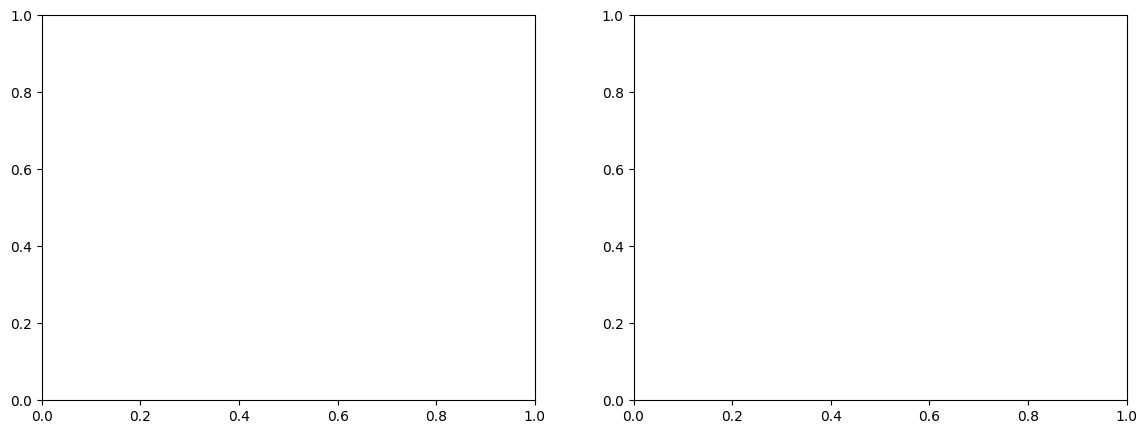

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(history["train_loss"], label="Train Loss", color="tomato")
axes[0].plot(history["val_loss"], label="Val Loss", color="steelblue")
axes[0].set_title("Loss Curves")
axes[0].legend(); axes[0].grid(True)

axes[1].plot(history["train_iou"], label="Train IoU", color="tomato")
axes[1].plot(history["val_iou"], label="Val IoU", color="steelblue")
axes[1].set_title("IoU Score Curves")
axes[1].legend(); axes[1].grid(True)

plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/training_curves_{MODEL_TAG}.png", dpi=120)
plt.show()
print(f"Best Val IoU: {best_val_iou:.4f}")


## Inference

Reloads the best checkpoint for `MODEL_NAME` and writes predicted masks to the model's own `MASK_DIR`.

In [12]:
model = build_model().to(device)
model.load_state_dict(torch.load(CKPT_PATH, map_location=device))
model = model.eval()
if FAMILY in ("dinov2", "mfuser"):
    set_backbone_trainable(model, False)
print("Loaded", CKPT_PATH)


@torch.no_grad()
def predict_and_save(img_id):
    img = cv2.cvtColor(cv2.imread(f"{DATA_DIR}/{img_id}_sat.jpg"), cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    aug = get_val_transforms(IMG_SIZE)(image=img, mask=np.zeros(img.shape[:2], dtype=np.float32))
    t = aug["image"].unsqueeze(0).to(device)
    logits = forward_logits(model, t)
    pred = (torch.sigmoid(logits) > 0.5).squeeze().cpu().numpy().astype(np.uint8) * 255
    if pred.shape != (h, w):
        pred = cv2.resize(pred, (w, h), interpolation=cv2.INTER_NEAREST)
    out_path = f"{MASK_DIR}/{img_id}_pred.png"
    cv2.imwrite(out_path, pred)
    return pred


DEMO_IDS = ["493626", "477671", "422265", "194764"]
demo_ids = [i for i in DEMO_IDS if i in val_ids or i in train_ids]
if not demo_ids:
    demo_ids = val_ids[:4]

for img_id in demo_ids:
    predict_and_save(img_id)
    print(f"Saved mask: {MASK_DIR}/{img_id}_pred.png")

from tqdm import tqdm

# Run only the first 40 val tiles instead of all of them
for img_id in tqdm(val_ids[:40]):
    predict_and_save(img_id)

print("Done. Masks in", MASK_DIR)
print("Phase II default reads masks_deeplab/ — copy masks here or change MASK_DIR in phase2_graph_healing.ipynb if using another model.")


DeepLabV3+ + ResNet34 + ASPP | Params: 22,437,457
Loaded /content/drive/MyDrive/RouteResilience/checkpoints/best_road_model_deeplabv3.pth
Saved mask: /content/drive/MyDrive/RouteResilience/outputs/masks_deeplab/493626_pred.png
Saved mask: /content/drive/MyDrive/RouteResilience/outputs/masks_deeplab/477671_pred.png
Saved mask: /content/drive/MyDrive/RouteResilience/outputs/masks_deeplab/422265_pred.png
Saved mask: /content/drive/MyDrive/RouteResilience/outputs/masks_deeplab/194764_pred.png


100%|██████████| 40/40 [01:00<00:00,  1.52s/it]

Done. Masks in /content/drive/MyDrive/RouteResilience/outputs/masks_deeplab
Phase II default reads masks_deeplab/ — copy masks here or change MASK_DIR in phase2_graph_healing.ipynb if using another model.


## Quick visual check

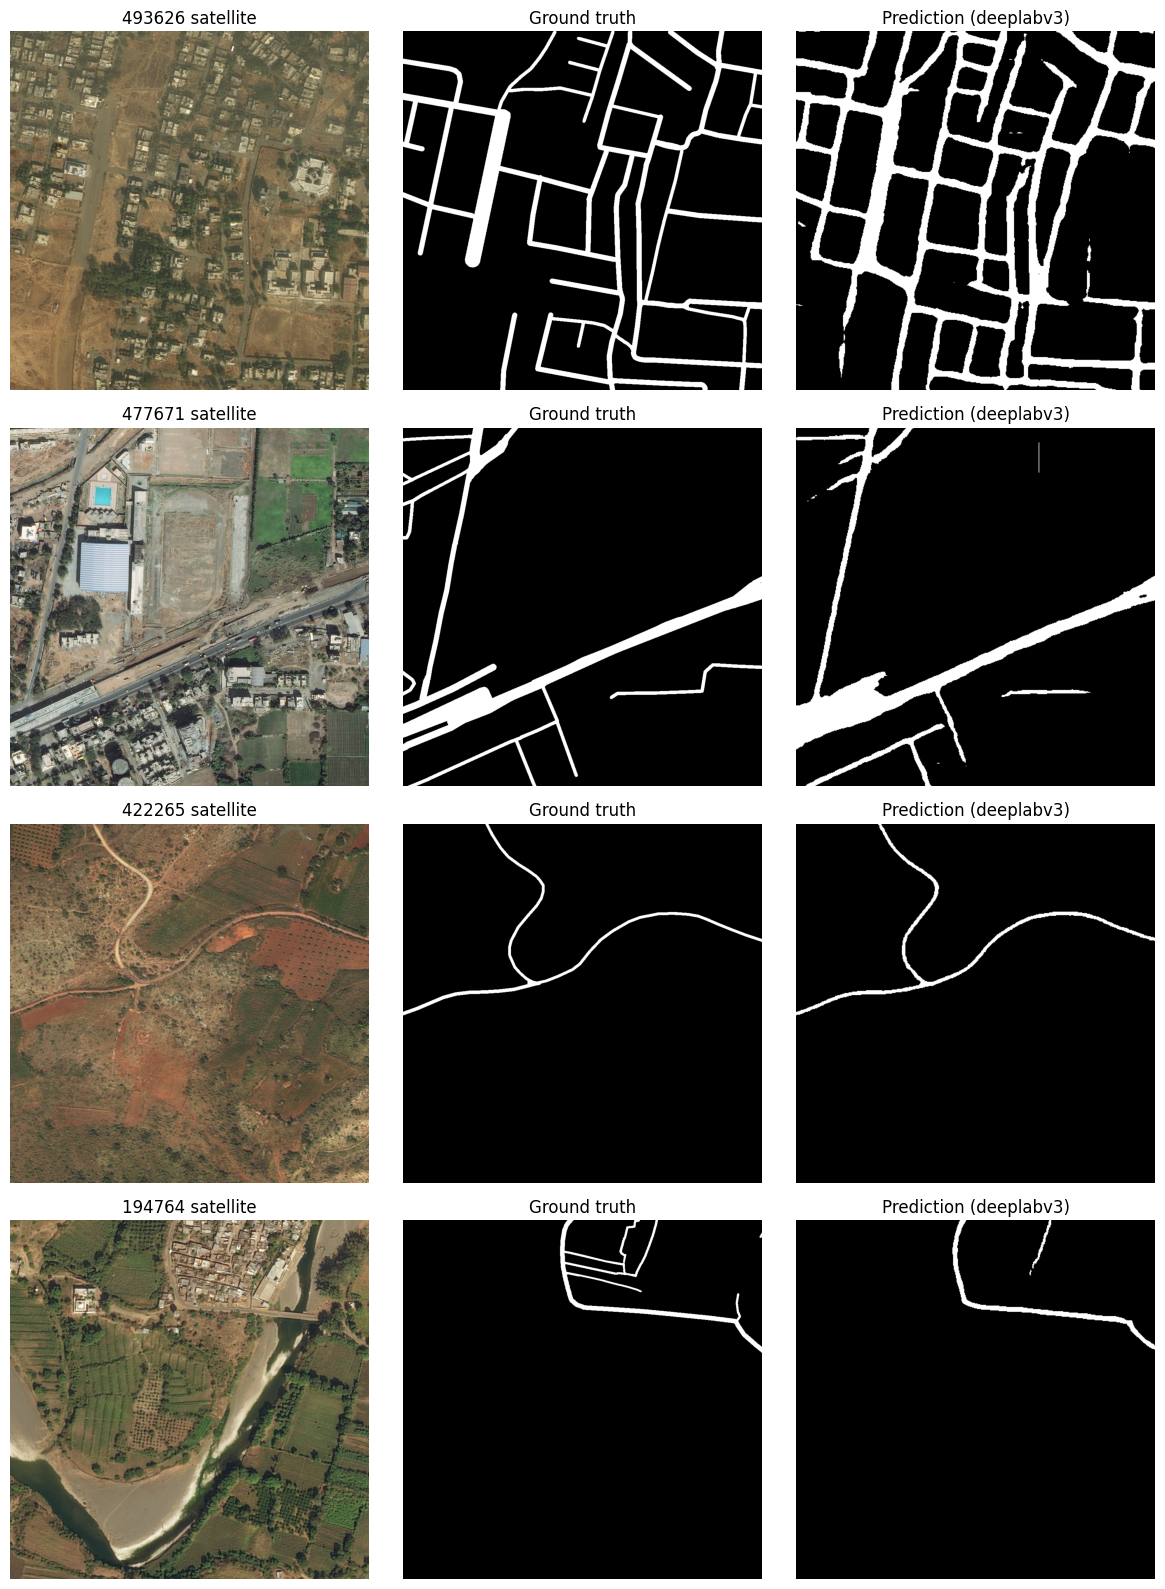

In [15]:
sample_ids = demo_ids[:4]
fig, axes = plt.subplots(len(sample_ids), 3, figsize=(12, 4 * len(sample_ids)))
if len(sample_ids) == 1:
    axes = axes.reshape(1, -1)

for row, img_id in enumerate(sample_ids):
    sat = cv2.cvtColor(cv2.imread(f"{DATA_DIR}/{img_id}_sat.jpg"), cv2.COLOR_BGR2RGB)
    gt = cv2.cvtColor(cv2.imread(f"{DATA_DIR}/{img_id}_mask.png"), cv2.COLOR_BGR2RGB)
    pred = cv2.imread(f"{MASK_DIR}/{img_id}_pred.png", cv2.IMREAD_GRAYSCALE)
    axes[row, 0].imshow(sat); axes[row, 0].set_title(f"{img_id} satellite"); axes[row, 0].axis("off")
    axes[row, 1].imshow(gt); axes[row, 1].set_title("Ground truth"); axes[row, 1].axis("off")
    axes[row, 2].imshow(pred, cmap="gray"); axes[row, 2].set_title(f"Prediction ({MODEL_TAG})"); axes[row, 2].axis("off")

plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/predictions_{MODEL_TAG}.png", dpi=120)
plt.show()


## Optional: SAM mask repair (post-processing, no retraining)

Runs after any model above has produced a mask folder. Reads from the current `MODEL_NAME`'s `MASK_DIR` by default (edit `INPUT_MASK_DIR` to point at a different model's masks) and writes repaired masks to `masks_sam_repaired/`. Unchanged from `phase1_sam_mask_repair.ipynb`, aside from wiring `INPUT_MASK_DIR` to the unified config.


Loading weights:   0%|          | 0/314 [00:00<?, ?it/s]

Loaded facebook/sam-vit-base
Input masks : /content/drive/MyDrive/RouteResilience/outputs/masks_deeplab
Output masks: /content/drive/MyDrive/RouteResilience/outputs/masks_sam_repaired


SAM repair:  25%|██▌       | 1/4 [01:22<04:08, 82.77s/it]

493626 | components 17->11 | largest-frac 0.991->0.990 | +pixels 109737


SAM repair:  50%|█████     | 2/4 [02:17<02:12, 66.09s/it]

477671 | components 9->5 | largest-frac 0.890->0.956 | +pixels 36443


SAM repair:  75%|███████▌  | 3/4 [02:50<00:51, 51.06s/it]

422265 | components 1->1 | largest-frac 1.000->1.000 | +pixels 9727


SAM repair: 100%|██████████| 4/4 [03:19<00:00, 49.82s/it]

194764 | components 3->2 | largest-frac 0.912->0.857 | +pixels 8787
Saved repaired masks to /content/drive/MyDrive/RouteResilience/outputs/masks_sam_repaired


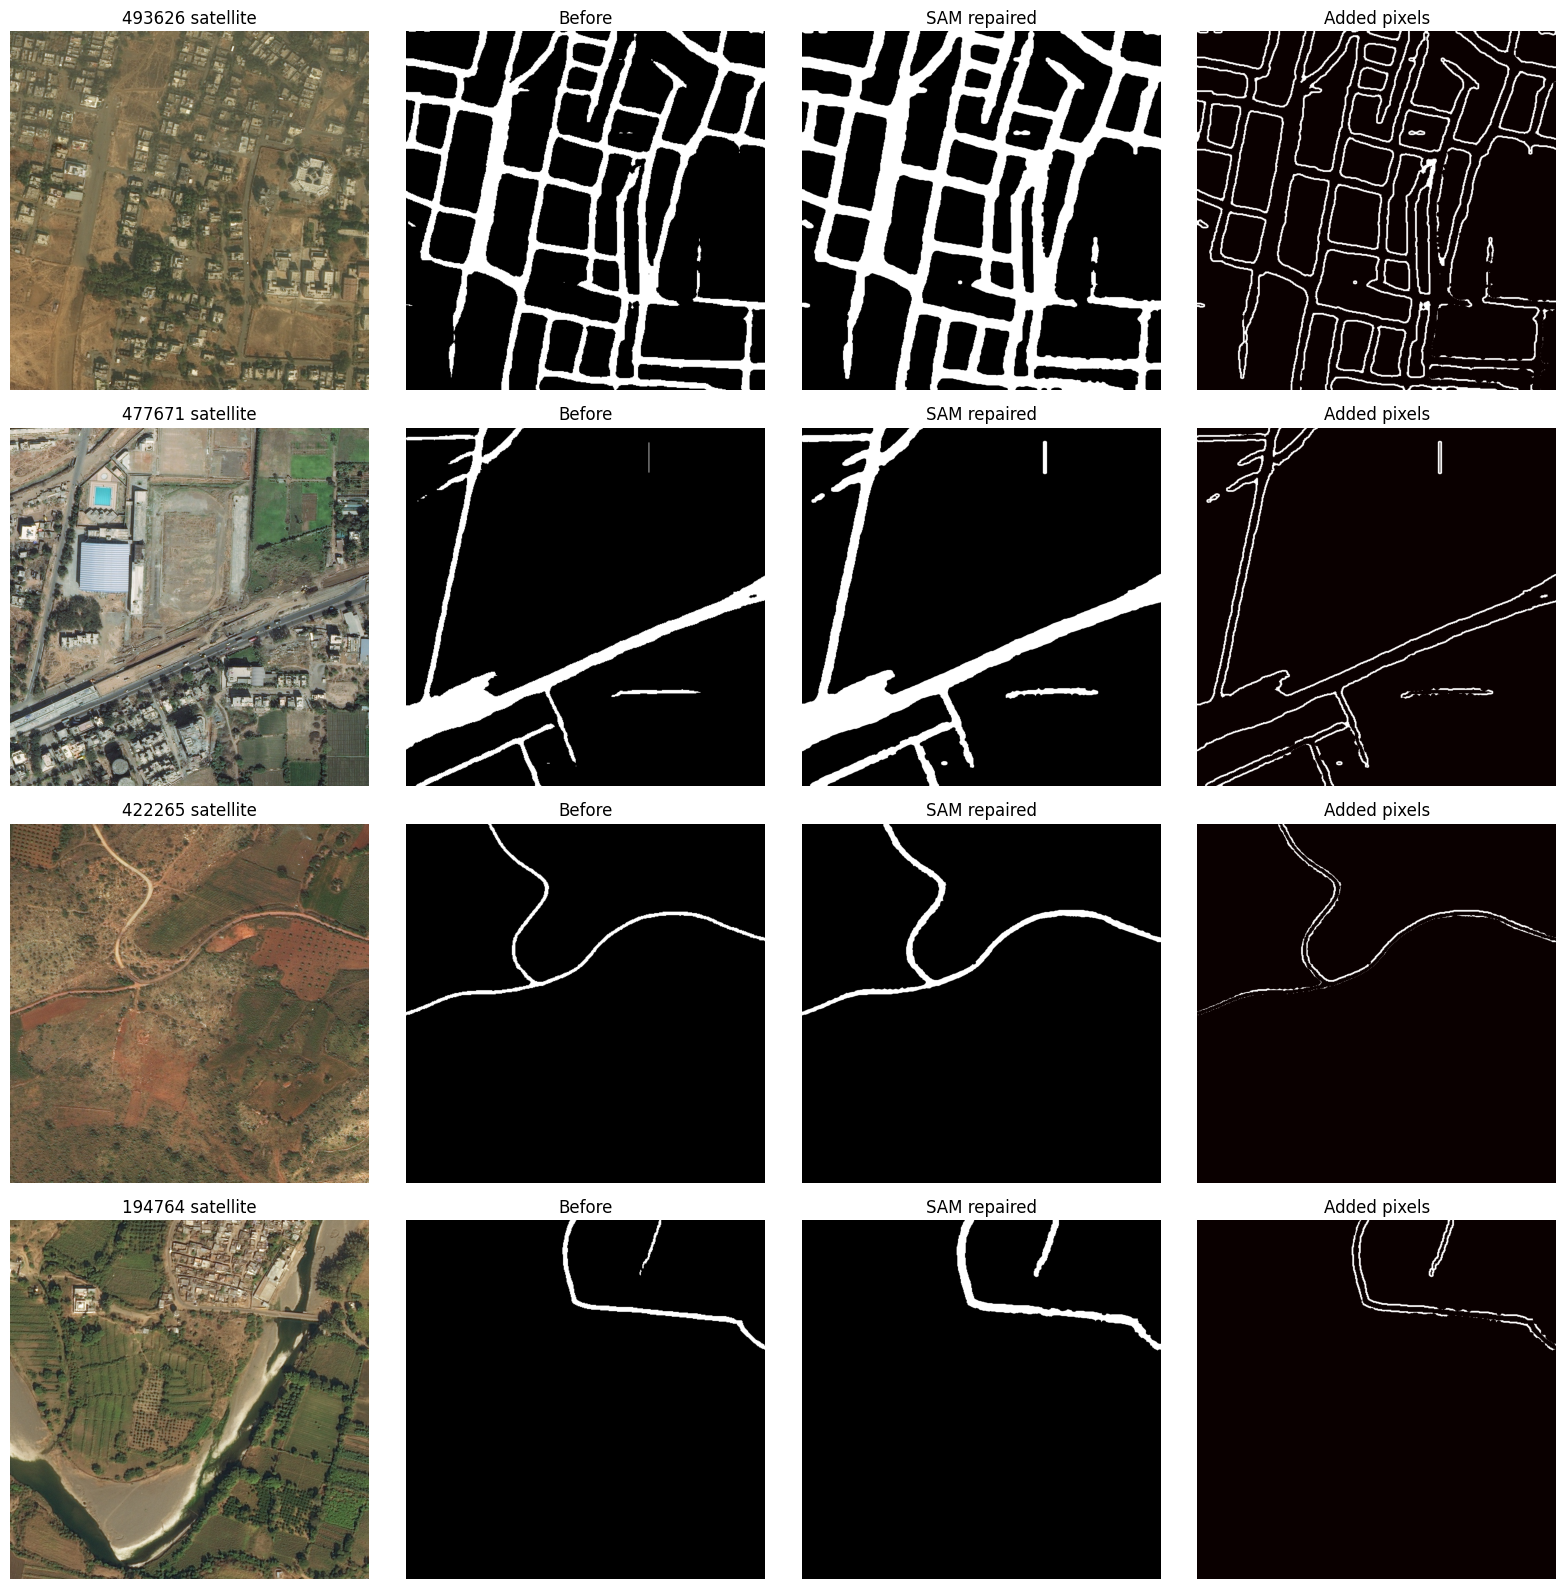

Phase II: set MASK_DIR to masks_sam_repaired or copy into masks_deeplab/


In [17]:
subprocess.run(["pip", "install", "-q", "transformers", "accelerate", "opencv-python", "matplotlib", "tqdm"], check=True)

# ============ CONFIG (edit if needed) ============
INPUT_MASK_DIR = MASK_DIR  # defaults to the masks just produced by MODEL_NAME above
OUTPUT_MASK_DIR = f"{DRIVE_BASE}/outputs/masks_sam_repaired"
SAM_MODEL_ID = "facebook/sam-vit-base"
SAM_DEMO_IDS = demo_ids if "demo_ids" in globals() else ["493626", "477671", "422265", "194764"]
RUN_ALL = False
# ================================================

os.makedirs(OUTPUT_MASK_DIR, exist_ok=True)
if not os.path.isdir(INPUT_MASK_DIR):
    raise FileNotFoundError(f"INPUT_MASK_DIR not found: {INPUT_MASK_DIR}")

from PIL import Image
from transformers import SamModel, SamProcessor

sam_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
processor = SamProcessor.from_pretrained(SAM_MODEL_ID)
sam = SamModel.from_pretrained(SAM_MODEL_ID).to(sam_device).eval()
print("Loaded", SAM_MODEL_ID)
print("Input masks :", INPUT_MASK_DIR)
print("Output masks:", OUTPUT_MASK_DIR)


def sample_points(xs, ys, n=12, seed=0):
    if len(xs) == 0:
        return []
    rng = np.random.default_rng(seed)
    idx = rng.choice(len(xs), size=min(n, len(xs)), replace=False)
    return [[int(xs[i]), int(ys[i])] for i in idx]


def gap_bridge_points(mask_bin, max_pairs=6):
    n_labels, labels = cv2.connectedComponents(mask_bin.astype(np.uint8))
    if n_labels <= 2:
        return []
    comps = []
    for lab in range(1, n_labels):
        ys, xs = np.where(labels == lab)
        if len(xs) < 50:
            continue
        comps.append((xs.mean(), ys.mean(), len(xs)))
    comps.sort(key=lambda x: x[2], reverse=True)
    comps = comps[:8]
    points = []
    for i in range(len(comps)):
        for j in range(i + 1, len(comps)):
            x1, y1 = comps[i][0], comps[i][1]
            x2, y2 = comps[j][0], comps[j][1]
            if np.hypot(x1 - x2, y1 - y2) > mask_bin.shape[0] * 0.45:
                continue
            points.append([int((x1 + x2) / 2), int((y1 + y2) / 2)])
            if len(points) >= max_pairs:
                return points
    return points


def connectivity_stats(mask_bin):
    n_labels, labels = cv2.connectedComponents(mask_bin.astype(np.uint8))
    areas = [(labels == i).sum() for i in range(1, n_labels)]
    total = mask_bin.sum()
    largest = max(areas) if areas else 0
    ratio = float(largest / total) if total > 0 else 0.0
    return n_labels - 1, ratio


def morph_fallback(mask_bin, k_close):
    return cv2.morphologyEx(mask_bin.astype(np.uint8), cv2.MORPH_CLOSE, k_close)


@torch.no_grad()
def repair_mask_with_sam(image_rgb, coarse_mask, seed=42):
    h, w = image_rgb.shape[:2]
    if coarse_mask.shape[:2] != (h, w):
        coarse_mask = cv2.resize(coarse_mask, (w, h), interpolation=cv2.INTER_NEAREST)
    mask_bin = (coarse_mask > 127).astype(np.uint8)
    k_small = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
    k_close = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (11, 11))

    if mask_bin.sum() == 0:
        return coarse_mask, np.zeros_like(mask_bin)

    road_core = cv2.erode(mask_bin, k_small, iterations=1)
    ys, xs = np.where(road_core > 0)
    if len(xs) < 5:
        ys, xs = np.where(mask_bin > 0)

    pos = sample_points(xs, ys, n=14, seed=seed)
    gap_pts = gap_bridge_points(mask_bin)

    dilated = cv2.dilate(mask_bin, k_close, iterations=2)
    bg_ys, bg_xs = np.where(dilated == 0)
    neg = sample_points(bg_xs, bg_ys, n=8, seed=seed + 1)

    if len(pos) == 0 and len(gap_pts) == 0:
        repaired = morph_fallback(mask_bin, k_close)
        return (repaired * 255).astype(np.uint8), np.zeros_like(mask_bin)

    all_pts = pos + gap_pts + neg
    all_labels = [1] * len(pos) + [1] * len(gap_pts) + [0] * len(neg)

    pil_image = Image.fromarray(image_rgb)
    inputs = processor(
        images=pil_image,
        input_points=[all_pts],
        input_labels=[all_labels],
        return_tensors="pt",
    )
    inputs = {k: v.to(sam_device) if hasattr(v, "to") else v for k, v in inputs.items()}

    out = sam(**inputs)
    masks = processor.image_processor.post_process_masks(
        out.pred_masks.detach().cpu(),
        inputs["original_sizes"].detach().cpu(),
        inputs["reshaped_input_sizes"].detach().cpu(),
    )[0]

    scores = out.iou_scores[0].detach().cpu().numpy().reshape(-1)
    if masks.ndim == 4:
        masks = masks[0]
    best_idx = int(scores.argmax())
    sam_mask = masks[best_idx].bool().cpu().numpy().astype(np.uint8)
    if sam_mask.shape != mask_bin.shape:
        sam_mask = cv2.resize(sam_mask, (w, h), interpolation=cv2.INTER_NEAREST)

    touch = cv2.dilate(mask_bin, k_close, iterations=1)
    sam_added = ((sam_mask & touch) | mask_bin).astype(np.uint8)
    repaired = morph_fallback(sam_added, k_close)
    return (repaired * 255).astype(np.uint8), (sam_mask * 255).astype(np.uint8)


# --- run repair ---
if RUN_ALL:
    tile_ids = [f.replace("_pred.png", "") for f in sorted(os.listdir(INPUT_MASK_DIR)) if f.endswith("_pred.png")]
else:
    tile_ids = SAM_DEMO_IDS

sam_results = []
for img_id in tqdm(tile_ids, desc="SAM repair"):
    sat_path = f"{DATA_DIR}/{img_id}_sat.jpg"
    in_path = f"{INPUT_MASK_DIR}/{img_id}_pred.png"
    out_path = f"{OUTPUT_MASK_DIR}/{img_id}_pred.png"

    if not os.path.exists(sat_path):
        print("skip (no sat):", img_id)
        continue
    if not os.path.exists(in_path):
        print("skip (no mask):", img_id)
        continue

    try:
        image = cv2.cvtColor(cv2.imread(sat_path), cv2.COLOR_BGR2RGB)
        coarse = cv2.imread(in_path, cv2.IMREAD_GRAYSCALE)
        repaired, _ = repair_mask_with_sam(image, coarse, seed=int(img_id) % 10000)
        cv2.imwrite(out_path, repaired)

        before_bin = (coarse > 127).astype(np.uint8)
        after_bin = (repaired > 127).astype(np.uint8)
        n_before, r_before = connectivity_stats(before_bin)
        n_after, r_after = connectivity_stats(after_bin)
        sam_results.append({
            "id": img_id,
            "components_before": n_before,
            "components_after": n_after,
            "largest_frac_before": r_before,
            "largest_frac_after": r_after,
            "pixels_added": int(after_bin.sum() - before_bin.sum()),
        })
        print(
            f"{img_id} | components {n_before}->{n_after} | "
            f"largest-frac {r_before:.3f}->{r_after:.3f} | +pixels {sam_results[-1]['pixels_added']}"
        )
    except Exception as e:
        print(f"ERROR on {img_id}: {type(e).__name__}: {e}")

if not sam_results:
    raise RuntimeError("No tiles repaired. Check INPUT_MASK_DIR and DATA_DIR.")

print("Saved repaired masks to", OUTPUT_MASK_DIR)

# --- before / after plot ---
fig, axes = plt.subplots(len(sam_results), 4, figsize=(16, 4 * len(sam_results)))
if len(sam_results) == 1:
    axes = axes.reshape(1, -1)

for row, r in enumerate(sam_results):
    img_id = r["id"]
    sat = cv2.cvtColor(cv2.imread(f"{DATA_DIR}/{img_id}_sat.jpg"), cv2.COLOR_BGR2RGB)
    before = cv2.imread(f"{INPUT_MASK_DIR}/{img_id}_pred.png", cv2.IMREAD_GRAYSCALE)
    after = cv2.imread(f"{OUTPUT_MASK_DIR}/{img_id}_pred.png", cv2.IMREAD_GRAYSCALE)
    h, w = sat.shape[:2]
    if before.shape[:2] != (h, w):
        before = cv2.resize(before, (w, h), interpolation=cv2.INTER_NEAREST)

    axes[row, 0].imshow(sat); axes[row, 0].set_title(f"{img_id} satellite"); axes[row, 0].axis("off")
    axes[row, 1].imshow(before, cmap="gray"); axes[row, 1].set_title("Before"); axes[row, 1].axis("off")
    axes[row, 2].imshow(after, cmap="gray"); axes[row, 2].set_title("SAM repaired"); axes[row, 2].axis("off")
    diff = ((after > 127).astype(np.uint8) - (before > 127).astype(np.uint8)).clip(0, 1)
    axes[row, 3].imshow(diff, cmap="hot"); axes[row, 3].set_title("Added pixels"); axes[row, 3].axis("off")

plt.tight_layout()
plt.savefig(f"{OUTPUT_MASK_DIR}/sam_repair_comparison.png", dpi=120)
plt.show()
print("Phase II: set MASK_DIR to masks_sam_repaired or copy into masks_deeplab/")
